# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024160059   # <-- your full roll number
NAME = "Diksha Mahajan"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160059   Name: Diksha Mahajan   Fingerprint: 9F8D860F   Tickets: 16

Ticket_ID                                                                                Ticket_Text
      T01                      Server failed to open after resetting my password. Please resolve it.
      T02                                                      The Wi-Fi works, but the VPN doesn't.
      T03                        The projector was working yesterday. The same problem occurs again.
      T04                                  The e-mail is not working. The same problem occurs again.
      T05                               The e-mail crashes while opening. Is there another solution?
      T06             I couldn't connect to the Python during the lab. It works on another computer.
      T07 I couldn't connect to the Python when I use mobile hotspot. The same problem occurs again.
      T08                               The laptop was working yesterday. Is there another solution?
     

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [12]:
# Your code

# Q1. Preprocessing Pipeline

import pandas as pd

results = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    ticket_text = row["Ticket_Text"]

    processed = process_ticket(ticket_text)

    results.append({
        "Ticket ID": ticket_id,
        "Sentences": len(processed["sentences"]),
        "Tokens": len(processed["tokens"]),
        "Punctuation": len(processed["punct"]),
        "Stopwords": len(processed["stops"]),
        "Unique Tokens": len(set(processed["tokens"])),
        "Final Tokens": len(processed["final"])
    })

# Create DataFrame
q1_table = pd.DataFrame(results)

# Calculate TOTAL row
total_row = {
    "Ticket ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation": q1_table["Punctuation"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": len(set(
        token
        for text in df["Ticket_Text"]
        for token in process_ticket(text)["tokens"]
    )),
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table.loc[len(q1_table)] = total_row

print("QUESTION 1: PREPROCESSING PIPELINE")
display(q1_table)

# Display actual tokens for one selected ticket
selected_ticket = df.iloc[0]
selected = process_ticket(selected_ticket["Ticket_Text"])

print("\nSelected Ticket:", selected_ticket["Ticket_ID"])
print("\nActual Tokens:")
print(selected["tokens"])

print("\nPunctuation Tokens:")
print(selected["punct"])

print("\nStopwords:")
print(selected["stops"])

print("\nFinal Tokens:")
print(selected["final"])


QUESTION 1: PREPROCESSING PIPELINE


,Ticket ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,13,2,4,12,7
1,T02,1,10,2,4,9,4
2,T03,2,12,2,5,10,5
3,T04,2,12,2,6,10,4
4,T05,2,11,2,4,11,5
5,T06,2,17,2,7,15,8
6,T07,2,19,2,8,16,9
7,T08,2,11,2,4,11,5
8,T09,2,14,2,5,14,7
9,T10,2,11,2,4,10,5



Selected Ticket: T01

Actual Tokens:
['server', 'failed', 'to', 'open', 'after', 'resetting', 'my', 'password', '.', 'please', 'resolve', 'it', '.']

Punctuation Tokens:
['.', '.']

Stopwords:
['to', 'after', 'my', 'it']

Final Tokens:
['server', 'failed', 'open', 'resetting', 'password', 'please', 'resolve']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [13]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

# Q2. Regular Expressions

import re

# Combine all raw tickets
all_text = " ".join(df["Ticket_Text"].tolist())

# 1. Words longer than 5 letters
long_words = re.findall(r"\b[A-Za-z]{6,}\b", all_text)

print("Words longer than 5 letters:")
print(long_words)

# 2. Numbers including decimals and versions
numbers = re.findall(
    r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?![\w.])",
    all_text
)

print("\nNumbers:")
print(numbers)

# 3. Capitalized words
capitalized_words = re.findall(r"\b[A-Z][a-zA-Z]*\b", all_text)

print("\nCapitalized Words:")
print(capitalized_words)

# 4. Words beginning with a vowel
vowel_words = re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", all_text)

print("\nWords Beginning with Vowels:")
print(vowel_words)


# TEST LINES
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

# 5. Replace email addresses, URLs and phone numbers

def clean_text(text):

    # Replace URLs
    text = re.sub(
        r"https?://[^\s]+|www\.[^\s]+",
        "<URL>",
        text
    )

    # Replace email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
    )

    # Replace phone numbers
    phone_pattern = (
        r"(?<!\w)(?:\+91[\s-]?)?"
        r"(?:\d{5}[\s-]\d{5}|\d{4}[-\s]\d{3}[-\s]\d{4})"
        r"(?!\w)"
    )

    text = re.sub(phone_pattern, "<PHONE>", text)

    return text


print("\nREPLACEMENT RESULTS:")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Modified:", clean_text(line))


# Apply replacement to all tickets
print("\nCLEANED TICKETS:")

for ticket in df["Ticket_Text"]:
    print(clean_text(ticket))


# Observation
print("\nCapitalized words may be capitalized only because")
print("they appear at the beginning of a sentence.")


Words longer than 5 letters:
['Server', 'failed', 'resetting', 'password', 'Please', 'resolve', 'projector', 'working', 'yesterday', 'problem', 'occurs', 'working', 'problem', 'occurs', 'crashes', 'opening', 'another', 'solution', 'couldn', 'connect', 'Python', 'during', 'another', 'computer', 'couldn', 'connect', 'Python', 'mobile', 'hotspot', 'problem', 'occurs', 'laptop', 'working', 'yesterday', 'another', 'solution', 'failed', 'before', 'assignment', 'deadline', 'another', 'solution', 'showing', 'worked', 'yesterday', 'closed', 'Matlab', 'asking', 'several', 'asking', 'Please', 'resolve', 'student', 'portal', 'asking', 'another', 'computer']

Numbers:
['3', '2', '30', '3.5', '1023', '03']

Capitalized Words:
['Server', 'Please', 'The', 'Wi', 'Fi', 'VPN', 'The', 'The', 'The', 'The', 'The', 'Is', 'I', 'Python', 'It', 'I', 'Python', 'I', 'The', 'The', 'Is', 'E', 'Is', 'The', 'It', 'The', 'Lab', 'The', 'Matlab', 'I', 'Only', 'PCs', 'The', 'Please', 'My', 'The', 'It']

Words Beginning w

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [15]:

# Q3. Custom Tokenizer

from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regular expression pattern
pattern = (
    r"https?://[^\s]+"
    r"|www\.[^\s]+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|\+91[\s-]?\d{5}[\s-]?\d{5}"
    r"|\d{4}[-\s]\d{3}[-\s]\d{4}"
    r"|\d{5}[\s-]\d{5}"
    r"|\d+(?:\.\d+)+"
    r"|[A-Za-z]+(?:-[A-Za-z]+)+"
    r"|[A-Za-z]+(?:'[A-Za-z]+)+"
    r"|[A-Za-z]+"
    r"|\d+"
    r"|[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


# Test on TEST_LINES
print("CUSTOM TOKENIZATION OF TEST LINES")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("My Tokenizer:", my_tokenize(line))
    print("Word Tokenize:", word_tokenize(line))


# Apply both tokenizers to all tickets
different_tickets = 0

print("\nCOMPARISON ON DATASET")

for _, row in df.iterrows():

    custom_tokens = my_tokenize(row["Ticket_Text"])
    nltk_tokens = word_tokenize(row["Ticket_Text"])

    if custom_tokens != nltk_tokens:
        different_tickets += 1

    print("\nTicket:", row["Ticket_ID"])
    print("Custom:", custom_tokens)
    print("NLTK:", nltk_tokens)

print("\nNumber of differently tokenized tickets:",
      different_tickets)


CUSTOM TOKENIZATION OF TEST LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My Tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Word Tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My Tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
Word Tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [16]:
# Your code

# Q4. Stemming and Lemmatization

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

# Initialize stemmers
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Regexp Stemmer
# Removes the suffix "ing"
regexp = RegexpStemmer("ing", min=4)

lemmatizer = WordNetLemmatizer()


# Collect unique final tokens
all_final_tokens = []

for ticket in df["Ticket_Text"]:
    processed = process_ticket(ticket)
    all_final_tokens.extend(processed["final"])

unique_words = sorted(set(all_final_tokens))


# POS tag all unique words
tagged_words = pos_tag(unique_words)


# Convert POS tags to WordNet POS
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    else:
        return "n"


results = []

for word, tag in tagged_words:

    pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    # Add only words with different outputs
    outputs = [
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ]

    if len(set(outputs)) > 1:

        results.append({
            "Original Word": word,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "POS Lemma": lemma_result
        })


# Display comparison table
q4_table = pd.DataFrame(results)

print("STEMMING AND LEMMATIZATION COMPARISON")
display(q4_table)


# Display suffix justification
print("\nREGEXP STEMMER JUSTIFICATION:")
print("The suffix 'ing' was selected because the dataset")
print("contains words such as working, opening, uploading,")
print("restarting and responding.")
print("Removing 'ing' helps identify their root forms.")


STEMMING AND LEMMATIZATION COMPARISON


,Original Word,Porter Stem,Lancaster Stem,Regexp Stem,POS Lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,closed,close,clos,closed,close
3,computer,comput,comput,computer,computer
4,crashes,crash,crash,crashes,crash
5,deadline,deadlin,deadlin,deadline,deadline
6,error,error,er,error,error
7,failed,fail,fail,failed,fail
8,hours,hour,hour,hours,hour
9,keeps,keep,keep,keeps,keep



REGEXP STEMMER JUSTIFICATION:
The suffix 'ing' was selected because the dataset
contains words such as working, opening, uploading,
restarting and responding.
Removing 'ing' helps identify their root forms.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All Tokens,194,88,0.4536
1,S2 - Without Punctuation,162,82,0.5062
2,S3 - Final Tokens,92,57,0.6196
3,S4 - Porter Stemming,92,54,0.5870



TOP 10 WORDS IN S1


,Word,Frequency
0,.,25
1,the,18
2,is,7
3,it,5
4,another,5
5,to,4
6,i,4
7,works,3
8,n't,3
9,working,3



TOP 10 WORDS IN S3


,Word,Frequency
0,another,5
1,works,3
2,n't,3
3,working,3
4,yesterday,3
5,problem,3
6,occurs,3
7,e-mail,3
8,solution,3
9,keeps,3


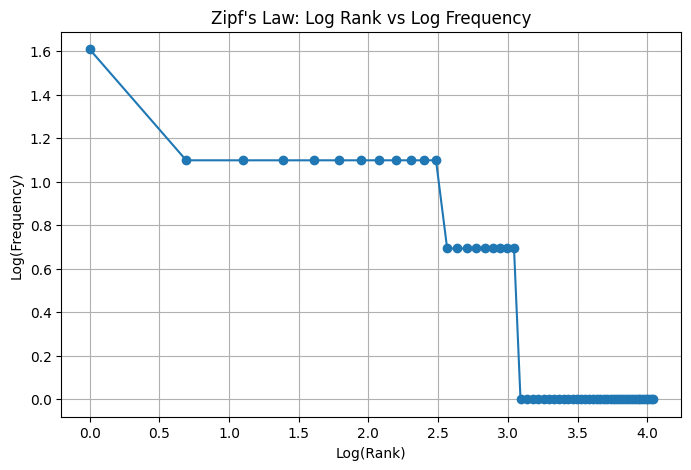


TOP 5 BIGRAMS IN S1


,Bigram,Frequency
0,"(., the)",12
1,"(., is)",4
2,"(yesterday, .)",3
3,"(the, same)",3
4,"(same, problem)",3



TOP 5 BIGRAMS IN S3


,Bigram,Frequency
0,"(problem, occurs)",3
1,"(another, solution)",3
2,"(keeps, asking)",3
3,"(asking, login)",3
4,"(failed, open)",2



TTR INTERPRETATION:
TTR changes from S1 to S4 because punctuation
and stopwords are removed and stemming combines
different forms of similar words.


In [18]:
# Your code

# Q5. Corpus Statistics

from collections import Counter
from nltk.util import bigrams
import matplotlib.pyplot as plt
import math

# S1: All tokens
S1 = []

# S2: Tokens without punctuation
S2 = []

# S3: Final tokens
S3 = []

for ticket in df["Ticket_Text"]:

    processed = process_ticket(ticket)

    S1.extend(processed["tokens"])

    S2.extend([
        token for token in processed["tokens"]
        if token not in processed["punct"]
    ])

    S3.extend(processed["final"])


# S4: S3 after Porter stemming
S4 = [porter.stem(word) for word in S3]


# Function to calculate corpus statistics
def corpus_statistics(name, tokens):

    total = len(tokens)
    unique = len(set(tokens))

    ttr = unique / total if total > 0 else 0

    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }


# Create statistics table
statistics = pd.DataFrame([
    corpus_statistics("S1 - All Tokens", S1),
    corpus_statistics("S2 - Without Punctuation", S2),
    corpus_statistics("S3 - Final Tokens", S3),
    corpus_statistics("S4 - Porter Stemming", S4)
])

print("CORPUS STATISTICS")
display(statistics)


# Top 10 words of S1
print("\nTOP 10 WORDS IN S1")

top_s1 = Counter(S1).most_common(10)

display(pd.DataFrame(
    top_s1,
    columns=["Word", "Frequency"]
))


# Top 10 words of S3
print("\nTOP 10 WORDS IN S3")

top_s3 = Counter(S3).most_common(10)

display(pd.DataFrame(
    top_s3,
    columns=["Word", "Frequency"]
))


# Zipf's Law Plot for S3
frequency = Counter(S3)

sorted_frequency = sorted(
    frequency.values(),
    reverse=True
)

ranks = range(1, len(sorted_frequency) + 1)

log_rank = [math.log(r) for r in ranks]
log_frequency = [math.log(f) for f in sorted_frequency]

plt.figure(figsize=(8, 5))

plt.plot(log_rank, log_frequency, marker='o')

plt.title("Zipf's Law: Log Rank vs Log Frequency")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True)

plt.show()


# Top 5 Bigrams of S1
print("\nTOP 5 BIGRAMS IN S1")

bigram_s1 = Counter(bigrams(S1)).most_common(5)

display(pd.DataFrame(
    bigram_s1,
    columns=["Bigram", "Frequency"]
))


# Top 5 Bigrams of S3
print("\nTOP 5 BIGRAMS IN S3")

bigram_s3 = Counter(bigrams(S3)).most_common(5)

display(pd.DataFrame(
    bigram_s3,
    columns=["Bigram", "Frequency"]
))


# Observation
print("\nTTR INTERPRETATION:")
print("TTR changes from S1 to S4 because punctuation")
print("and stopwords are removed and stemming combines")
print("different forms of similar words.")


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR (Type-Token Ratio) measures vocabulary diversity and is calculated as the number of unique tokens divided by the total number of tokens.

TTR changes from S1 to S4 because of the preprocessing steps:

- **S1:** Contains all tokens, including punctuation and stopwords.
- **S2:** Removes punctuation tokens, changing the total and unique token counts.
- **S3:** Removes stopwords and applies preprocessing, leaving the final tokens.
- **S4:** Applies Porter stemming, which combines different word forms into common stems, reducing the number of unique tokens.

Therefore, stemming generally reduces vocabulary diversity and lowers TTR. However, removing punctuation and stopwords may increase or decrease TTR depending on the dataset.